# 06 – Le passage à l'échelle : PaySim (6,36 millions de transactions)

**Question :** le même pipeline fonctionne-t-il sur un vrai volume, et que vaut le modèle sur un jeu de référence ?

**PaySim** (Kaggle, `ealaxi/paysim1`) est un simulateur publié, calibré sur un mois de journaux réels d'un service de Mobile Money africain.
On le convertit au format du projet, puis on l'entraîne **avec exactement le même code** :
```bash
python -m src.generator.paysim_adapter                     # -> data/transactions_paysim.csv
python -m src.ml.train_model --data data/transactions_paysim.csv --algo rf --out models/paysim
bash scripts/cluster.sh up && docker exec momo-spark-app python3 -m src.ml.train_model \
     --data data/transactions_paysim.csv --algo rf --out models/paysim_cluster
```
Limites assumées : PaySim ne contient ni appareil, ni ville, ni canal ; l'adaptateur les ajoute de façon stable par compte et **indépendante de la fraude** (aucun signal, aucune fuite).

In [1]:
# Préparation : on travaille depuis la racine du projet pour importer src/ et config/
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E3E7EF", "axes.axisbelow": True})
AMBRE, ROUGE, TURQUOISE, GRIS = "#E89A00", "#E5384A", "#1BA597", "#C9D2E3"

In [2]:
import json, re
from pyspark.sql import functions as F
from src.ml.features import TX_SCHEMA
from src.ml.spark import get_spark

spark = get_spark("notebook-paysim", conf={"spark.driver.memory": "4g", "spark.ui.showConsoleProgress": "false"})
ps = spark.read.csv("data/transactions_paysim.csv", header=True, schema=TX_SCHEMA).cache()
n, n_fraude = ps.count(), ps.filter("is_fraud = 1").count()
print(f"{n:,} transactions, {n_fraude:,} fraudes ({n_fraude / n:.3%})".replace(",", " "))

6 362 539 transactions  8 197 fraudes (0.129%)


## 1. Où sont les fraudes ?

In [3]:
par_type = (ps.groupBy("tx_type").agg(F.count("*").alias("transactions"), F.sum("is_fraud").alias("fraudes"))
            .withColumn("taux (%)", F.round(F.col("fraudes") / F.col("transactions") * 100, 3)).orderBy(F.desc("fraudes")))
par_type.toPandas()

,tx_type,transactions,fraudes,taux (%)
0,CASH_OUT,2278914,4100,0.180
1,TRANSFER,532909,4097,0.769
2,CASH_IN,1399281,0,0.000
3,PAYMENT,2151435,0,0.000


## 2. Une différence majeure avec nos données : presque pas d'historique par compte
Dans PaySim, la plupart des comptes n'émettent **qu'une seule transaction** sur le mois. Les profils de comptes et les features de fréquence, décisives sur nos données, n'ont donc presque rien à exploiter ici.

In [4]:
par_compte = ps.groupBy("sender_id").count()
repartition = (par_compte.withColumn("opérations", F.when(F.col("count") >= 3, "3 ou plus").otherwise(F.col("count").cast("string")))
               .groupBy("opérations").agg(F.count("*").alias("comptes")).orderBy("opérations").toPandas())
repartition["part des comptes (%)"] = (repartition["comptes"] / repartition["comptes"].sum() * 100).round(2)
repartition

,opérations,comptes,part des comptes (%)
0,1,6343928,99.85
1,2,9283,0.15
2,3 ou plus,15,0.00


## 3. Ce qui trahit la fraude dans PaySim : la comptabilité des soldes
On compare, pour les transactions normales et frauduleuses, la part de comptes vidés et la part de soldes incohérents (solde après ≠ solde avant − montant).

In [5]:
erreurs = (ps.withColumn("solde_vidé", F.col("sender_balance_after") == 0)
           .withColumn("incohérence", F.abs(F.col("sender_balance_before") - F.col("amount") - F.col("sender_balance_after")) > 1)
           .groupBy("is_fraud").agg(F.round(F.avg(F.col("solde_vidé").cast("int")) * 100, 1).alias("solde vidé (%)"),
                                     F.round(F.avg(F.col("incohérence").cast("int")) * 100, 1).alias("solde incohérent (%)"))
           .orderBy("is_fraud").toPandas())
erreurs

,is_fraud,solde vidé (%),solde incohérent (%)
0,0,56.7,78.7
1,1,98.0,0.5


Lecture : les fraudes vident presque toujours le compte (98 %) **avec une comptabilité exacte**, alors que la majorité des transactions normales
ont des soldes incohérents. C'est une particularité connue du simulateur PaySim : elle suffit presque à séparer les deux classes.

## 4. Résultats : une machine contre le cluster
**Une leçon de passage à l'échelle.** Sur nos données, la table des profils (environ 16 000 comptes) est copiée sur chaque executor
(*broadcast join*) : la jointure est immédiate. Sur PaySim, la table des profils de test compte plus de 5 millions de comptes ; le premier essai sur le cluster a échoué
(`notEnoughMemoryToBuildAndBroadcastTable`) car la table ne tenait plus dans la mémoire du driver. Au-delà de 500 000 comptes,
`train_model` fait désormais une **jointure répartie** (chaque executor ne traite que sa part des comptes). À l'échelle d'un opérateur,
les profils vivraient dans une base clé-valeur répartie (HBase, Redis) interrogée par le scoring.

In [6]:
def duree(log):
    m = re.search(r"durée=(\d+) s", open(log).read())
    return int(m.group(1)) if m else None

lignes = []
for mode, dossier, log in (("local[*] (8 cœurs, 1 JVM de 6 Go)", "models/paysim", "logs/train_paysim_local.log"),
                           ("cluster (2 executors × 2 cœurs × 1 Go)", "models/paysim_cluster", "logs/train_paysim_cluster.log")):
    try:
        m = json.load(open(f"{dossier}/metrics.json"))
    except FileNotFoundError:
        continue
    lignes.append({"mode": mode, "durée totale (s)": duree(log), "transactions d'entraînement": m["n_train"],
                   "AUC-PR test": round(m["auc_pr"], 3), "rappel (seuil 0,50)": f"{m['at_medium']['recall']:.0%}",
                   "précision (seuil 0,80)": f"{m['at_high']['precision']:.0%}"})
pd.DataFrame(lignes).set_index("mode")

,durée totale (s),transactions d'entraînement,AUC-PR test,"rappel (seuil 0,50)","précision (seuil 0,80)"
mode,,,,,
"local[*] (8 cœurs, 1 JVM de 6 Go)",653,1906746,1.0,100%,100%
cluster (2 executors × 2 cœurs × 1 Go),893,1908206,1.0,100%,100%


Test : 1 277 661 transactions dont 4 242 fraudes (hasard : AUC-PR = 0.0033)


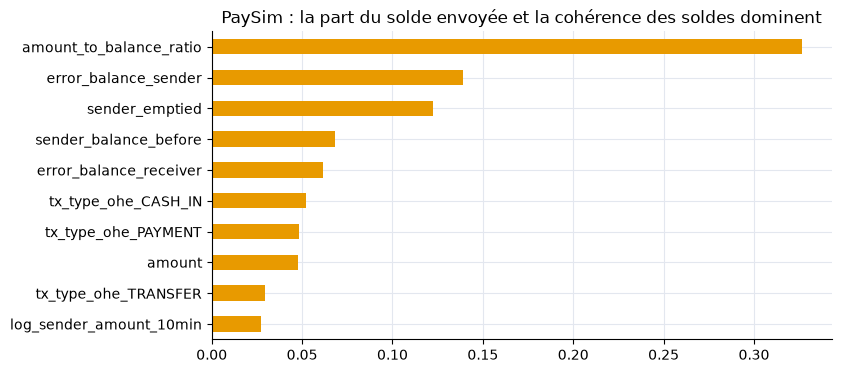

In [7]:
m = json.load(open("models/paysim/metrics.json"))
print(f"Test : {m['n_test']:,} transactions dont {m['n_test_fraud']:,} fraudes (hasard : AUC-PR = {m['fraud_rate_test']:.4f})".replace(",", " "))
imp = pd.DataFrame(m["feature_importances"]).head(10).iloc[::-1]
ax = imp.plot.barh(x="feature", y="importance", color=AMBRE, legend=False, figsize=(8, 4),
                   title="PaySim : la part du solde envoyée et la cohérence des soldes dominent")
ax.set_ylabel(""); plt.show()

## Ce qu'il faut retenir
- Le **même code** traite 6,36 millions de transactions, en local comme sur le cluster : c'est l'intérêt de Spark.
- Sur PaySim, le modèle détecte presque toutes les fraudes, mais grâce à la **part du solde envoyée et à la comptabilité des soldes**, une particularité de ce simulateur, et non grâce aux habitudes des comptes (99,85 % des comptes n'y font qu'une transaction). Un score aussi élevé est donc à relativiser : il ne prouve pas que le modèle détecterait des fraudes réelles plus subtiles.
- Sur une seule machine, le cluster (4 cœurs, 2 Go pour les executors) a été **plus lent** que le mode local (8 cœurs, 6 Go) sur ce volume : un cluster ne crée pas de ressources, il permet d'en ajouter en ajoutant des machines.
- Nos données simulées sont plus exigeantes (arnaques, fractionnements, comptes avec historique) : c'est sur elles que nous évaluons l'intérêt des profils et de la fréquence.

In [8]:
spark.stop()